# Step 1

In [1]:
import numpy as np

def simulate_global_state(
        T=100_000,
        D=256,
        mu=-1.5,
        sigma=0.3,
        sigma_drift=0.001,
        seed=42
):
    rng = np.random.default_rng(seed)

    # base logits for each bit
    alpha = rng.normal(mu, sigma, size=D)
    beta = rng.normal(mu, sigma, size=D)

    # drift term
    eps = np.zeros(D)

    # state matrix
    X = np.zeros((T, D), dtype=np.int8)

    #initial state
    X[0] = rng.binomial(1, 0.5, size=D)

    for t in range(1, T):
        # update drift
        eps += rng.normal(0, sigma_drift, size=D)

        # Transition probabilities
        p = 1 / (1 + np.exp(-(alpha + eps)))
        q = 1 / (1 + np.exp(-(beta+eps)))

        prev = X[t-1]

        # transition
        prob_1 = np.where(prev == 0, p, 1 - q)
        X[t] = rng.binomial(1, prob_1)
        
    return X

# sanity check for step 1

In [2]:
# simulate shorter run for sanity check
X = simulate_global_state(T=50_000, seed=123)

# 1. Marginal entropy
def binary_entropy(p):
    p = np.clip(p, 1e-6, 1-1e-6)
    return -p*np.log2(p) - (1-p)*np.log2(1-p)

marginal_means = X.mean(axis=0)
entropies = binary_entropy(marginal_means)

# 2. Autocorrelation at lag 1 (agreement rate)
autocorr = np.mean(X[1:] == X[:-1], axis=0)

# 3. drift: rolling mean for first 5 bits
window = 2000
rolling_means = np.array([
    np.convolve(X[:, i], np.ones(window)/window, mode="valid")
    for i in range(5)
])

entropies.mean(), entropies.min(), entropies.max(), autocorr.mean(), rolling_means[:, :5] 

(0.9790799336568075,
 0.8114365822407562,
 0.9999999065133593,
 0.816445078901578,
 array([[0.363 , 0.3625, 0.3625, 0.362 , 0.3615],
        [0.588 , 0.588 , 0.588 , 0.588 , 0.5875],
        [0.621 , 0.621 , 0.6215, 0.622 , 0.622 ],
        [0.5995, 0.6   , 0.6005, 0.601 , 0.6015],
        [0.525 , 0.5255, 0.5255, 0.5255, 0.5255]]))

# Step 2

In [3]:
import numpy as np

def construct_nodes(
        D=256,
        K=40,
        subset_size=25,
        overlap_target=5,
        seed=123
):
    """
    Construct K subsets of size 25 from {1,...,D} with controlled overlap.
    """
    rng = np.random.default_rng(seed)
    subsets = []

    # first subset purely random
    first = rng.choice(D, subset_size, replace=False)
    subsets.append(set(first))

    for _ in range(1, K):
        # pick overlap_target indices from an existing subset
        base = rng.choice(list(subsets[rng.integers(len(subsets))]),
                          overlap_target,
                          replace=False)
        remaining = subset_size - overlap_target
        rest = rng.choice(
            list(set(range(D)) - set(base)),
            remaining,
            replace=False
        )
        subsets.append(set(base) | set(rest))

    return subsets

def compute_node_signals(X, subsets):
    """
    X: (T, D)
    subsets: list of index sets
    returns Z: (T, K)
    """
    T = X.shape[0]
    K = len(subsets)
    Z = np.zeros((T, K))
    for k, S in enumerate(subsets):
        Z[:, k] = X[:, list(S)].mean(axis=1)
    return Z

# ----- apply to previously simulated X for sanity check -----
X = simulate_global_state(T=50_000, seed=123)

subsets = construct_nodes()
Z = compute_node_signals(X, subsets)

# sanity checks
Z.shape, np.mean(np.std(Z, axis=0)), np.corrcoef(Z.T)[:5, :5]

((50000, 40),
 0.09873110160122327,
 array([[1.        , 0.24965878, 0.32152542, 0.20969827, 0.08591754],
        [0.24965878, 1.        , 0.03943882, 0.44474304, 0.20664913],
        [0.32152542, 0.03943882, 1.        , 0.1131155 , 0.03752906],
        [0.20969827, 0.44474304, 0.1131155 , 1.        , 0.27578669],
        [0.08591754, 0.20664913, 0.03752906, 0.27578669, 1.        ]]))

# Step 3

In [4]:
import numpy as np

# ------- step1: global state ----------
def simulate_global_state(
    T=50_000,
    D=256,
    mu=-1.5,
    sigma=0.3,
    sigma_drift=0.001,
    seed=123
):
    rng = np.random.default_rng(seed)
    alpha = rng.normal(mu, sigma, size=D)
    beta = rng.normal(mu, sigma, size=D)
    eps = np.zeros(D)
    X = np.zeros((T, D), dtype=np.int8)
    X[0] = rng.binomial(1, 0.5, size=D)

    for t in range(1, T):
        eps += rng.normal(0, sigma_drift, size=D)
        p = 1 / (1 + np.exp(-(alpha + eps)))
        q = 1 / (1 + np.exp(-(beta + eps)))
        prev = X[t - 1]
        prob_1 = np.where(prev == 0, p, 1 - q)
        X[t] = rng.binomial(1, prob_1)

    return X

# -------- step2: nodes ----------
def construct_nodes(
    D=256,
    K=40,
    subset_size=25,
    overlap_target=5,
    seed=123
):
    rng = np.random.default_rng(seed)
    subsets = []
    subsets.append(set(rng.choice(D, subset_size, replace=False)))

    for _ in range(1, K):
        base_subset = subsets[rng.integers(len(subsets))]
        base = rng.choice(list(base_subset), overlap_target, replace=False)
        rest = rng.choice(list(set(range(D)) - set(base)), subset_size - overlap_target, replace=False)
        subsets.append(set(base) | set(rest))
    return subsets

def compute_node_signals(X, subsets):
    T = X.shape[0]
    K = len(subsets)
    Z = np.zeros((T, K), dtype=np.float32)
    for k, S in enumerate(subsets):
        Z[:, k] = X[:, list(S)].mean(axis=1)
    return Z

# ----- step3: correlation network -----
def build_correlation_network(Z, tau=0.2, use_abs=True):
    W = np.corrcoef(Z.T)
    W = np.nan_to_num(W)
    A = ((np.abs(W) > tau) if use_abs else (W > tau)).astype(np.int8)
    np.fill_diagonal(A, 0)
    # undirected graph: symmetrize
    A = np.maximum(A, A.T)
    return W,A

def graph_stats(A):
    K = A.shape[0]
    edges = int(A.sum() // 2)
    density = edges / (K * (K - 1)/2)

    # components via DFS
    visited = np.zeros(K, dtype=bool)
    comp_sizes = []
    for i in range(K):
        if visited[i]:
            continue
        stack = [i]
        visited[i] = True
        size = 0
        while stack:
            v = stack.pop()
            size += 1
            for n in np.where(A[v] == 1)[0]:
                if not visited[n]:
                    visited[n] = True
                    stack.append(n)
        comp_sizes.append(size)
    comp_sizes.sort(reverse=True)

    deg = A.sum(axis=1)
    L = np.diag(deg) - A
    evals = np.linalg.eigvalsh(L)
    evals.sort()
    lambda2 = float(evals[1]) if K > 1 else 0.0

    return {
        "K": K,
        "edges": edges,
        "density": float(density),
        "largest_components": int(comp_sizes[0]),
        "num_components": int(len(comp_sizes)),
        "lambda2_algebraic_connectivity": lambda2,
        "mean_degree": float(deg.mean()),
        "min_degree": int(deg.min()),
        "max_degree": int(deg.max()),
        "component_sizes_top5": comp_sizes[:5],
    }

# ----- run ------
X = simulate_global_state()
subsets = construct_nodes()
Z = compute_node_signals(X, subsets)

taus = [0.10, 0.20, 0.30, 0.40]
summary = []
for tau in taus:
    W, A = build_correlation_network(Z, tau=tau, use_abs=True)
    s = graph_stats(A)
    s["tau"] = tau
    summary.append(s)

summary



[{'K': 40,
  'edges': 397,
  'density': 0.5089743589743589,
  'largest_components': 40,
  'num_components': 1,
  'lambda2_algebraic_connectivity': 11.256115651242151,
  'mean_degree': 19.85,
  'min_degree': 13,
  'max_degree': 29,
  'component_sizes_top5': [40],
  'tau': 0.1},
 {'K': 40,
  'edges': 90,
  'density': 0.11538461538461539,
  'largest_components': 40,
  'num_components': 1,
  'lambda2_algebraic_connectivity': 0.4781078842137398,
  'mean_degree': 4.5,
  'min_degree': 1,
  'max_degree': 12,
  'component_sizes_top5': [40],
  'tau': 0.2},
 {'K': 40,
  'edges': 16,
  'density': 0.020512820512820513,
  'largest_components': 7,
  'num_components': 24,
  'lambda2_algebraic_connectivity': -3.9019543131195757e-16,
  'mean_degree': 0.8,
  'min_degree': 0,
  'max_degree': 3,
  'component_sizes_top5': [7, 4, 3, 3, 2],
  'tau': 0.3},
 {'K': 40,
  'edges': 3,
  'density': 0.0038461538461538464,
  'largest_components': 3,
  'num_components': 37,
  'lambda2_algebraic_connectivity': 0.0,
  '

# Step 4

In [5]:
import numpy as np

# ----- minimal regeneration -----
def simulate_global_state(
    T=10_000,
    D=356,
    seed=123
):
    rng = np.random.default_rng(seed)
    alpha = rng.normal(-1.5, 0.3, size=D)
    beta = rng.normal(-1.5, 0.3, size=D)
    eps = np.zeros(D)
    X = np.zeros((T, D), dtype=np.int8)
    X[0] = rng.binomial(1, 0.5, size=D)
    for t in range(1, T):
        eps += rng.normal(0, 0.001, size=D)
        p = 1 / (1 + np.exp(-(alpha + eps)))
        q = 1 / (1 + np.exp(-(beta + eps)))
        X[t] = rng.binomial(1, np.where(X[t-1] == 0, p, 1-q))
    return X

def construct_nodes(
    D=256,
    K=40,
    subset_size=25,
    overlap_target=5,
    seed=123
):
    rng = np.random.default_rng(seed)
    subsets = [set(rng.choice(D, subset_size, replace=False))]
    for _ in range(1, K):
        base = rng.choice(list(subsets[rng.integers(len(subsets))]),
        overlap_target, replace=False)
        rest = rng.choice(list(set(range(D)) - set(base)),
        subset_size - overlap_target, replace=False)
        subsets.append(set(base) | set(rest))
    return subsets

def compute_node_signals(X, subsets):
    Z = np.zeros((X.shape[0], len(subsets)), dtype=np.float32)
    for k, S in enumerate(subsets):
        Z[:, k] = X[:, list(S)].mean(axis=1)
    return Z

def prepare_masked_sequences(Z, window=128, mask_ratio=0.15, seed=123):
    rng = np.random.default_rng(seed)
    T, K = Z.shape
    N = T - window
    X_masked = np.zeros((N, window, K), dtype=np.float32)
    mask = np.zeros((N, window, K), dtype=bool)

    for i in range(N):
        X_masked[i] = Z[i:i+window]
        m = rng.random((window, K)) < mask_ratio
        mask[i] = m
        X_masked[i][m] = 0.0

    return X_masked, mask

# --- run ---
X = simulate_global_state()
subsets = construct_nodes()
Z = compute_node_signals(X, subsets)

X_masked, mask = prepare_masked_sequences(Z)
X_masked.shape, mask.mean()

((9872, 128, 40), 0.1500514594623683)

# Step 5

In [ ]:
import numpy as np

# ---------- step 1-2 helper code ----------
def simulate_global_state(
    T=20_000,
    D=256,
    seed=123,
    mu=-1.5,
    sigma=0.3,
    sigma_drift=0.001
):
    rng = np.random.default_rng(seed)
    alpha = rng.normal(mu, sigma, size=D)
    beta = rng.normal(mu, sigma, size=D)
    eps = np.zeros(D)
    X = np.zeros((T, D), dtype=np.int8)
    X[0] = rng.binomial(1, 0.5, size=D)
    for t in range(1, T):
        eps += rng.normal(0, sigma_drift, size=D)
        p = 1 / (1 + np.exp(-(alpha + eps)))
        q = 1 / (1 + np.exp(-(beta + eps)))
        X[t] = rng.binomial(1, np.where(X[t-1]==0, p, 1-q))
    return X

def construct_nodes(
    D=256,
    K=40,
    subset_size=25,
    overlap_target=5,
    seed=123
):
    rng = np.random.default_rng(seed)
    subsets = [set(rng.choice(D, subset_size, replace=False))]
    for _ in range(1, K):
        base_subset = subsets[rng.integers(len(subsets))]
        base = rng.choice(list(base_subset), overlap_target, replace=False)
        rest = rng.choice(list(set(range(D)) - set(base)), subset_size - overlap_target, replace=False)
        subsets.append(set(base) | set(rest))
    return subsets

def compute_node_signals(X, subsets):
    Z = np.zeros((X.shape[0], len(subsets)), dtype=np.float32)
    for k, S in enumerate(subsets):
        Z[:, k] = X[:, list(S)].mean(axis=1)
    return Z

# ---------- step 5: Destruction operators ----------
def destroy_bitflip_X(X, delta, seed=0):
    rng = np.random.default_rng(seed)
    flips = rng.random(X.shape) < delta
    X_tilde = X.copy()
    X_tilde[flips] = 1 - X_tilde[flips]
    return X_tilde

def destroy_dropout_Z(Z, delta, seed=0):
    rng = np.random.default_rng(seed)
    drop = rng.random(Z.shape) < delta
    Z_tilde = Z.copy()
    Z_tilde[drop] = 0.0
    return Z_tilde

def destroy_shuffle_time(Z, delta, seed=0):
    rng = np.random.default_rng(seed)
    T = Z.shape[0]
    m = int(delta * T)
    if m<= 1:
        return Z.copy()
    idx = np.arange(T)
    pick = rng.choice(T, size=m, replace=False)
    perm = pick.copy()
    rng.shuffle(perm)
    idx[pick] = idx[perm]
    return Z[idx].copy()

# ----- diagnostics -----
def corr_summary(Z):
    W = np.corrcoef(Z.T)
    W = np.nan_to_num(W)
    K = W.shape[0]
    offdiag = W[~np.eye(K, dtype=bool)]
    return float(offdiag.mean()), float(np.median(np.abs(offdiag))), float(np.max(np.abs(offdiag)))

def lag1_corr_mean(Z):
    Z0, Z1 = Z[:-1], Z[1:]
    c = []
    for k in range(Z.shape[1]):
        a, b = Z0[:, k], Z1[:, k]
        sa, sb = np.std(a), np.std(b)
        if sa < 1e-8 or sb < 1e-8:
            c.append(0.0)
        else:
            c.append(np.corrcoef(a, b)[0, 1])
    return float(np.mean(c))

# ----- run -----
X = simulate_global_state(T=20_000, seed=123)
subsets = construct_nodes(seed=123)
Z = compute_node_signals(X, subsets)

# ------ apply bit-flip destruction and observe effects on Z ----
deltas = [0.0, 0.05, 0.10, 0.20, 0.30]
report_bitflip = []
for d in deltas:
    Xd = destroy_bitflip_X(X, d, seed=999)
    Zd = compute_node_signals(Xd, subsets)
    cmean, absmed, absmax, = corr_summary(Zd)
    report_bitflip.append({
        "delta": d,
        "lag1_corr_mean": lag1_corr_mean(Zd),
        "crosscorr_abs_median": absmed,
        "crosscorr_abs_max": absmax,
        "Z_std_mean": float(np.mean(np.std(Zd, axis=0))),
    })

# ------ compare alternative destruction modes on Z directly ----
d = 0.20
Z_drop = destroy_dropout_Z(Z, d, seed=999)
Z_shuf = destroy_shuffle_time(Z, d, seed=999)

compare_modes = {
    "base": {
        "lag1_corr_mean": lag1_corr_mean(Z),
        "crosscorr_abs_median": corr_summary(Z)[1],
        "crosscorr_abs_max": corr_summary(Z)[2],
    },
    "dropout_Z (delta=0.20)": {
        "lag1_corr_mean": lag1_corr_mean(Z_drop),
        "crosscorr_abs_median": corr_summary(Z_drop)[1],
        "crosscorr_abs_max": corr_summary(Z_drop)[2],
    },
    "shuffle_time (delta=0.20)": {
        "lag1_corr_mean": lag1_corr_mean(Z_shuf),
        "crosscorr_abs_median": corr_summary(Z_shuf)[1],
        "crosscorr_abs_max": corr_summary(Z_shuf)[2],
    }
}

report_bitflip, compare_modes

([{'delta': 0.0,
   'lag1_corr_mean': 0.6274454040169737,
   'crosscorr_abs_median': 0.10279180345693455,
   'crosscorr_abs_max': 0.4468658213079473,
   'Z_std_mean': 0.09874514490365982},
  {'delta': 0.05,
   'lag1_corr_mean': 0.5044888007967238,
   'crosscorr_abs_median': 0.1045780333063708,
   'crosscorr_abs_max': 0.4445460363834786,
   'Z_std_mean': 0.09906663000583649},
  {'delta': 0.1,
   'lag1_corr_mean': 0.3966320016160307,
   'crosscorr_abs_median': 0.10680022208905564,
   'crosscorr_abs_max': 0.4415357885162578,
   'Z_std_mean': 0.09924716502428055},
  {'delta': 0.2,
   'lag1_corr_mean': 0.22010953254304616,
   'crosscorr_abs_median': 0.10717837621982934,
   'crosscorr_abs_max': 0.44349355873168234,
   'Z_std_mean': 0.0995275229215622},
  {'delta': 0.3,
   'lag1_corr_mean': 0.09715681673921958,
   'crosscorr_abs_median': 0.10861849909523905,
   'crosscorr_abs_max': 0.4422877024955696,
   'Z_std_mean': 0.09970051050186157}],
 {'base': {'lag1_corr_mean': 0.6274454040169737,
   

# Step 6

In [7]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# ----- Dataset: sliding window + random masks (step 4) ------
class MaskedWindowDataset(Dataset):
    def __init__(self, Z, window=128, mask_ratio=0.15, seed=123):
        rng = np.random.default_rng(seed)
        T, K = Z.shape
        self.Z = Z.astype(np.float32)
        self.window = window
        self.N = T - window
        self.K = K
        # pre-generate masks for reproducibility
        self.masks = rng.random((self.N, window, K)) < mask_ratio

    def __len__(self):
        return self.N

    def __getitem__(self, idx):
        x = self.Z[idx:idx+self.window].copy()  # (L,K)
        m = self.masks[idx]                     # (L,K) bool
        y = x.copy()                            # masked input value
        x[m] = 0.0
        return torch.from_numpy(x), torch.from_numpy(m), torch.from_numpy(y)

def masked_mse(yhat, y, mask):
    m = mask.float()
    return (((yhat - y) ** 2) * m).sum() / m.sum().clamp_min(1.0)

# ---- model: transformer encoder over time ----
# ---- token = time step; features = K nodes ----
class MaskedTimeTransformer(nn.Module):
    def __init__(self, K, window=128, d_model=128, nhead=4, num_layers=3, dim_ff=256, dropout=0.1):
        super().__init__()
        self.in_proj = nn.Linear(K, d_model)
        self.pos_emb = nn.Parameter(torch.randn(window, d_model) * 0.02)

        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_ff,
            dropout=dropout,
            batch_first=True,
            activation="gelu",
        )
        self.encoder = nn.TransformerEncoder(layer, num_layers=num_layers)
        self.out_proj = nn.Linear(d_model, K)

    def forward(self, x):
        # x: (B, L, K)
        B, L, _ = x.shape
        h = self.in_proj(x) + self.pos_emb[:L].unsqueeze(0)
        h = self.encoder(h)
        return self.out_proj(h)

# ----- training loop (step 6)-----
def train_masked_transformer(
    Z,
    window=128,
    mask_ratio=0.15,
    epochs=5,
    batch_size=64,
    lr=3e-4,
    seed=0
):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    
    # time split (no leakage)
    T = Z.shape[0]
    split = int(0.8 * T)
    Z_train = Z[:split]
    Z_val = Z[split - window:] # keep overlap so first val window is valid
    
    train_ds = MaskedWindowDataset(Z_train, window=window, mask_ratio=mask_ratio, seed=seed+1)
    val_ds = MaskedWindowDataset(Z_val, window=window, mask_ratio=mask_ratio, seed=seed+2)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=0)

    model = MaskedTimeTransformer(K=Z.shape[1], window=window).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)

    @torch.no_grad()
    def eval_loss(loader):
        model.eval()
        losses = []
        for xb, mb, yb in loader:
            xb, mb, yb = xb.to(device).float(), mb.to(device), yb.to(device).float()
            losses.append(masked_mse(model(xb), yb, mb).item())
        model.train()
        return float(np.mean(losses))

    history = []
    for ep in range(1, epochs+1):
        for xb, mb, yb in train_loader:
            xb, mb, yb = xb.to(device).float(), mb.to(device), yb.to(device).float()
            opt.zero_grad(set_to_none=True)
            yhat = model(xb)
            loss = masked_mse(yhat, yb, mb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()

        tr = eval_loss(train_loader)
        va = eval_loss(val_loader)
        history.append((ep, tr, va))
        print(f"epoch {ep:02d} | train masked MSE {tr:.6f} | val masked MSE {va:.6f}")

    return model, history, Z_train, val_loader, device

In [8]:
import torch
print(torch.__version__)
print(torch.nn)


2.5.1+cu121
<module 'torch.nn' from 'd:\\PythonEnvs\\tf_gpu\\lib\\site-packages\\torch\\nn\\__init__.py'>


In [9]:
import torch
import torch.nn as nn

print("torch version:", torch.__version__)
print("nn module:", nn)


torch version: 2.5.1+cu121
nn module: <module 'torch.nn' from 'd:\\PythonEnvs\\tf_gpu\\lib\\site-packages\\torch\\nn\\__init__.py'>


# Pre Step 7

In [10]:
import json
import numpy as np
import torch

# ---- baseline models ----
def baseline_global_node_mean(Z_train):
    """
    Returns per-node computed on training time series.
    Z_train: (T_train, K)
    """
    return Z_train.mean(axis=0) # (K,)

def baseline_predict_global_mean(mu, shape):
    """
    mu: (K,)
    shape: (B, L, K)
    returns yhat: (B, L, K)
    """
    B, L, K = shape
    return np.broadcast_to(mu.reshape(1, 1, K), (B, L, K)).copy()

def baseline_predict_window_node_mean(x_masked_np):
    """
    Baseline A: for each node k, predict mean over time in the window.
    x_masked_np: (B, L, K)
    returns yhat: (B, L, K)
    """
    node_means = x_masked_np.mean(axis=1, keepdims=True) # (B, L, K)
    return np.repeat(node_means, x_masked_np.shape[1], axis=1)

def masked_mse_np(yhat, y_true, mask_bool):
    """
    yhat, y_true: (B, L, K) float arrays
    mask_bool: (B, L, K) bool array (True where masked)
    """
    m = mask_bool.astype(np.float32)
    num = ((yhat - y_true) ** 2 * m).sum()
    den = m.sum() + 1e-8
    return float(num / den)

# ---- unified evaluation ----

@torch.no_grad()
def eval_transformer_masked_mse(model, loader, device):
    """
    Evaluates masked MSE for the transformer.
    Assumes your torch masked_mse(yhat, y, mask) exists.
    """
    model.eval()
    losses = []
    for xb, mb, yb in loader:
        xb = xb.to(device).float()
        mb = mb.to(device)
        yb = yb.to(device).float()
        yhat = model(xb)
        losses.append(masked_mse(yhat, yb, mb).item())
    model.train()
    return float(np.mean(losses))

def eval_baselines_masked_mse(loader, mu_train=None):
    """
    Evaluates Baseline A (window-node-mean) and Baseline B (global-node-mean).
    loader yields xb, mb, yb as torch tensors.
    mu_train: (K,) or none, if none, skips global-mean baseline.
    Returns dict with baseline losses.
    """
    losses_window = []
    losses_global = []

    for xb, mb, yb in loader:
        x = xb.numpy().astype(np.float32) # masked inputs
        m = mb.numpy().astype(bool)       # mask
        y = yb.numpy().astype(np.float32) # true

        # baseline A
        yhat_w = baseline_predict_window_node_mean(x)
        losses_window.append(masked_mse_np(yhat_w, y, m))

        # baseline B
        if mu_train is not None:
            yhat_g = baseline_predict_global_mean(mu_train, x.shape)
            losses_global.append(masked_mse_np(yhat_g, y, m))

    out = {"baseline_window_node_mean": float(np.mean(losses_window))}
    if mu_train is not None:
        out["baseline_global_node_mean"] = float(np.mean(losses_global))
    return out


# ---- save/load model helpers -----

def save_model_and_history(model, history, path_prefix="run1"):
    """
    Saves:
    - model weights: <prefix>_model.pt
    - training history: <prefix>_history.json
    """
    torch.save(model.state_dict(), f"{path_prefix}_model.pt")

    # history can be list of tuples or list of dicts
    if len(history) > 0 and isinstance(history[0], tuple):
        hist_obj = [{"epoch":e, "train_masked_mse": tr, "val_masked_mse": va} for (e, tr, va) in history]
    else:
        hist_obj = history

    with open(f"{path_prefix}_history.json", "w") as f:
        json.dump(hist_obj, f, indent=2)

def load_model_weights(model, weights_path, map_location="cpu"):
    """
    loads weights into an *already constructed* model with same architecture.
    """
    state = torch.load(weights_path, map_location=map_location)
    model.load_state_dict(state)
    return model

def save_delta_sweep(results, path="delta_sweep_results.json"):
    """
    results: list of dicts.
    [{"delta":0.0, "val_mse_transformer":..., "val_mse_baseline_window":..., ...}, ...]
    """
    with open(path, "w") as f:
        json.dump(results, f, indent=2)

# ----- one-call pre-step-7 evaluation on your validation loader
def pre_step7_evaluate(model, Z_train, val_loader, device):
    """
    computes:
    - transformer val masked mse
    - baseline A val masked mse
    - baseline b val masked mse (global_node mean)
    """
    mu = baseline_global_node_mean(Z_train)  # (K,)
    tf_loss = eval_transformer_masked_mse(model, val_loader, device)
    base_losses = eval_baselines_masked_mse(val_loader, mu_train=mu)

    out = {"transformer_val_masked_mse": tf_loss}
    out.update(base_losses)
    return out


In [11]:
model, history, Z_train, val_loader, device = train_masked_transformer(
    Z,
    window=128,
    mask_ratio=0.15
)

metrics = pre_step7_evaluate(model, Z_train, val_loader, device)
print(metrics)

save_model_and_history(model, history, path_prefix="run1_clean")


epoch 01 | train masked MSE 0.010039 | val masked MSE 0.010065
epoch 02 | train masked MSE 0.009600 | val masked MSE 0.009601
epoch 03 | train masked MSE 0.009321 | val masked MSE 0.009318
epoch 04 | train masked MSE 0.009189 | val masked MSE 0.009190
epoch 05 | train masked MSE 0.009119 | val masked MSE 0.009114
{'transformer_val_masked_mse': 0.009114415917013372, 'baseline_window_node_mean': 0.01612281483164231, 'baseline_global_node_mean': 0.00977521799189225}


first results:
epoch 01 | train masked MSE 0.010070 | val masked MSE 0.010087\
epoch 02 | train masked MSE 0.009695 | val masked MSE 0.009720\
epoch 03 | train masked MSE 0.009461 | val masked MSE 0.009478\
epoch 04 | train masked MSE 0.009288 | val masked MSE 0.009275\
epoch 05 | train masked MSE 0.009174 | val masked MSE 0.009158\
{'transformer_val_masked_mse': 0.00915775749654997,
'baseline_window_node_mean': 0.01612281483164231,
'baseline_global_node_mean': 0.00977521799189225}

# Step 7

In [12]:
# ---- 7.3 discretization ----
def discretize(x, bins):
    return np.digitize(x, bins) -1

In [13]:
# ---- 7.4 Entropy utilities -----
import numpy as np

def entropy_from_counts(counts):
    p = counts / counts.sum()
    p = p[p > 0]
    return -np.sum(p * np.log2(p))

def joint_entropy(x, y):
    xy = np.stack([x, y], axis=1)
    _, counts = np.unique(xy, axis=0, return_counts=True)
    return entropy_from_counts(counts)

def conditional_entropy(x, y): 
    # H(x|y) = H(x,y) - H(y)
    _, cy = np.unique(y, return_counts=True)
    return joint_entropy(x, y) - entropy_from_counts(cy)

def mutual_information(x, y):
    _, cx = np.unique(x, return_counts=True)
    return entropy_from_counts(cx) - conditional_entropy(x, y)

In [14]:
# ----- 7.5: collect masked predictions -----
@torch.no_grad()
def collect_masked_predictions(model, loader, device):
    model.eval()
    z_true, z_pred = [], []

    for xb, mb, yb in loader:
        xb = xb.to(device).float()
        mb = mb.numpy().astype(bool)
        yb = yb.numpy()

        yhat = model(xb).cpu().numpy()

        z_true.append(yb[mb])
        z_pred.append(yhat[mb])

    return np.concatenate(z_true), np.concatenate(z_pred)

# and for baseline (window-node-mean) we have:
def collect_baseline_predictions(loader):
    z_true, z_pred = [], []

    for xb, mb, yb in loader:
        x = xb.numpy()
        m = mb.numpy().astype(bool)
        y = yb.numpy()

        yhat = baseline_predict_window_node_mean(x)

        z_true.append(y[m])
        z_pred.append(yhat[m])
    
    return np.concatenate(z_true), np.concatenate(z_pred)

In [16]:
# ----- 7.6: compute information metrics -------
bins = np.linspace(0, 1, 21)

z_t, z_p = collect_masked_predictions(model, val_loader, device)

zt_d = discretize(z_t, bins)
zp_d = discretize(z_p, bins)

H_cond = conditional_entropy(zt_d, zp_d)
MI = mutual_information(zt_d, zp_d)

print("H(Z | Z_hat) =", H_cond)
print("I(Z ; Z_hat) =", MI)
print("Normalized retention =", MI / entropy_from_counts(np.unique(zt_d, return_counts=True)[1]))

H(Z | Z_hat) = 2.928351318243976
I(Z ; Z_hat) = 0.056133810959317465
Normalized retention = 0.018808541014343184


In [ ]:
# ------- 7.7: delta sweep ------- 
## ------ phase transitions part -----
# in this stage, we repeat steps 5 to 7 for increasing delta


# constants reused from Step 6
window = 128
mask_ratio = 0.15
split = int(0.8 * Z.shape[0])

results = []

for delta in [0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    Xd = destroy_bitflip_X(X, delta, seed=999)
    Zd = compute_node_signals(Xd, subsets)

# rebuild validation loader with same window and mask
Z_val_d = Zd[split - window:]
val_ds_d = MaskedWindowDataset(Z_val_d, window=window, mask_ratio=mask_ratio, seed=2)
val_loader_d = DataLoader(val_ds_d, batch_size=64, shuffle=False)

zt, zp = collect_masked_predictions(model, val_loader_d, device)
zt_d = discretize(zt, bins)
zp_d = discretize(zp, bins)

MI = mutual_information(zt_d, zp_d)

results.append({
    "delta": delta,
    "mutual_information": MI
})

In [23]:
print(results)

[{'delta': 0.3, 'mutual_information': 0.03804331203777389}]


In [20]:
print(Z_val_d.shape)  # should be (something > window, K)


(4128, 40)


In [27]:
# --- helper functions to collect baseline masked predictions ----
import numpy as np
import torch
from torch.utils.data import DataLoader
import json
import matplotlib.pyplot as plt

def collect_baseline_window_predictions(val_loader):
    z_true, z_pred = [], []
    for xb, mb, yb in val_loader:
        x = xb.numpy().astype(np.float32)
        m = mb.numpy().astype(bool)
        y = yb.numpy().astype(np.float32)

        yhat = baseline_predict_window_node_mean(x) # (B, L, K)
        z_true.append(y[m])
        z_pred.append(yhat[m])

    return np.concatenate(z_true), np.concatenate(z_pred)

In [ ]:
# ----- sweep: compute ml + retention for trasformer and baseline ----
def H_from_samples(discrete_samples):
    _, counts = np.unique(discrete_samples, return_counts=True)
    return entropy_from_counts(counts)

results = []

for delta in [0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]:
    # 1) destroy world -> recompute node series
    Xd = destroy_bitflip_X(X, delta, seed=999)
    Zd = compute_node_signals(Xd, subsets)

    # 2) build val loader on destroyed data (same protocol as step 6/7)
    Z_val_d = Zd[split-window:] # keep overlap so first window is valid
    val_ds_d = MaskedWindowDataset(Z_val_d, window=window, mask_ratio=mask_ratio, seed=2)
    val_loader_d = DataLoader(val_ds_d, batch_size=64, shuffle=False, num_workers=0)

    # 3) Transformer masked samples
    zt_tf, zp_tf = collect_masked_predictions(model, val_loader_d, device)
    
    zt_tf_d = discretize(zt_tf, bins)
    zp_tf_d = discretize(zp_tf, bins)

    H_true = H_from_samples(zt_tf_d)
    MI_tf = mutual_information(zt_tf_d, zp_tf_d)
    R_tf = (MI_tf / H_true) if H_true > 1e-12 else 0

    # 4) baseline masked samples (window-node-mean)
    zt_b, zp_b = collect_baseline_window_predictions(val_loader_d)
    zt_b_d = discretize(zt_b, bins)
    zp_b_d = discretize(zp_b, bins)

    # H_true should match (up to sampling noise); reuse H_true from transformer samples
    MI_b = mutual_information(zt_b_d, zp_b_d)
    R_b = (MI_b / H_true) if H_true > 1e-12 else 0.0

    results.append({
        "delta": float(delta),
        "H_true": float(H_true),
        "MI_transformer": float(MI_tf),
        "R_transformer": float(R_tf),
        "MI_baseline_window": float(MI_b),
        "R_baseline_window": float(R_b),
    })

    results[:2], results[-1]

In [29]:
# --- save results in json file -----
with open("step7_delta_sweep_info.json", "w") as f:
    json.dump(results, f, indent=2)
print("Saved: step7_delta_sweep_info_metrics.json")

Saved: step7_delta_sweep_info_metrics.json


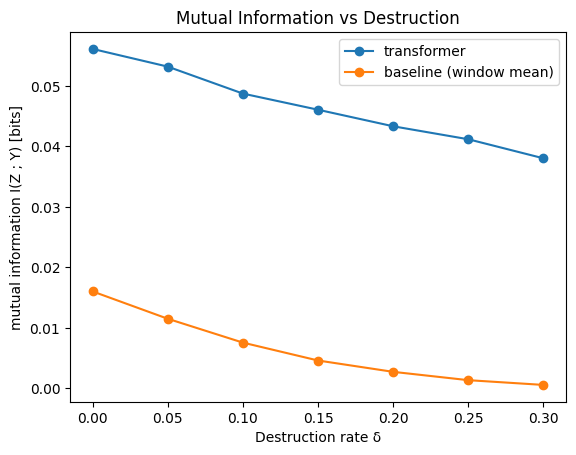

In [31]:
# ------ plot MI vs Delta & Retention vs Delta
# MI plot
deltas = [r["delta"] for r in results]
mi_tf = [r["MI_transformer"] for r in results]
mi_b = [r["MI_baseline_window"] for r in results]

plt.figure()
plt.plot(deltas, mi_tf, marker="o")
plt.plot(deltas, mi_b, marker="o")
plt.xlabel("Destruction rate δ")
plt.ylabel("mutual information I(Z ; Y) [bits]")
plt.title("Mutual Information vs Destruction")
plt.legend(["transformer", "baseline (window mean)"])
plt.show()

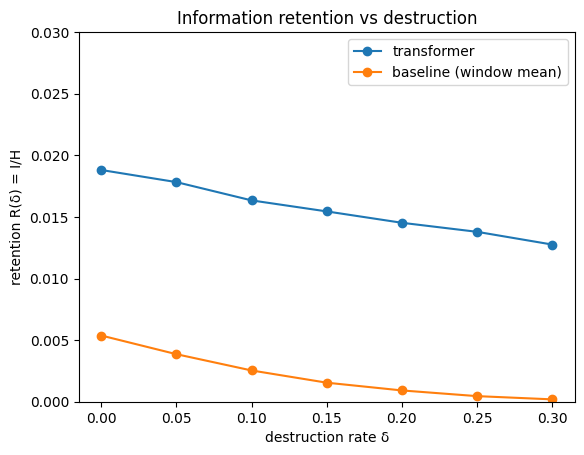

In [37]:
# Retention plot R(delta) = I / H
r_tf = [r["R_transformer"] for r in results]
r_b = [r["R_baseline_window"] for r in results]

plt.figure()
plt.plot(deltas, r_tf, marker="o")
plt.plot(deltas, r_b, marker="o")
plt.xlabel("destruction rate δ")
plt.ylabel("retention R(δ) = I/H")
plt.title("Information retention vs destruction")
plt.legend(["transformer", "baseline (window mean)"])
#plt.ylim(-0.05, 1.05)
plt.ylim(0, 0.03)
plt.show()

If you want a sharper “failure point” later (optional)
You now have a working pipeline.
If you ever want a sharper transition:

* Use dropout destruction on Z instead of bit-flips on X
Or
* time-shuffle destruction
Or
* increase drift speed

Those will produce:

* sudden MI collapse
* transformer and baseline curves merging rapidly
* a visually obvious δ*

But that’s an extension, not a fix.

# three rigorous ways to define a formal failure threshold δ*

In [42]:
# ----- 1) failure when transformer advantage disappears ----
def failure_threshold_gap(results, alpha=0.2, use_key="R"):
    # use_key can be "R" or "MI"
    tf_key = f"{use_key}_transformer"
    b_key = f"{use_key}_baseline_window"

    deltas = np.array([r["delta"] for r in results], dtype=float)
    gap = np.array([r[tf_key] - r[b_key] for r in results], dtype=float)

    gap0 = gap[0]
    target = alpha * gap0

    # find first crossing 
    for i in range(1, len(deltas)):
        if gap[i] <= target:
            # interpolate between i-1 and i
            d0, d1 = deltas[i-1], deltas[i]
            g0, g1 = gap[i-1], gap[i]
            if g1 == g0:
                return float(d1)
            return float(d0 + (target - g0) * (d1 - d0) / (g1 - g0))
        
    return None # never crossed in your grid

In [43]:
delta_star = failure_threshold_gap(results, alpha=0.2, use_key="R")
print("delta* (gap-retention, 20% rule):", delta_star)

delta* (gap-retention, 20% rule): None


In [44]:
# ------ 2) Failure when retention falls below an absolute floor ----
def failure_threshold_absolute(results, eps=0.01):
    deltas = np.array([r["delta"] for r in results], dtype=float)
    Rtf = np.array([r["R_transformer"] for r in results], dtype=float)

    for i in range(1, len(deltas)):
        if Rtf[i] <= eps:
            d0, d1 = deltas[i-1], deltas[i]
            r0, r1 = Rtf[i-1], Rtf[i]
            if r1 == r0:
                return float(d1)
            return float(d0 + (eps - r0) * (d1- d0) / (r1 - r0))
    return None

In [45]:
delta_star_abs = failure_threshold_absolute(results, eps=0.01)
print("delta* (R <= 1%):", delta_star_abs)

delta* (R <= 1%): None


In [46]:
# ------ 3) failure at the "knee point" (phase transition) ----
def failure_threshold_knee(results, key="R_transformer"):
    deltas = np.array([r["delta"] for r in results], dtype=float)
    y = np.array([r[key] for r in results], dtype=float)

    # need at least 3 points
    if len(y) < 3:
        return None
    
    # second diffrence (assumes roughly uniform delta spacing)
    second = y[:-2] - 2*y[1:-1] + y[2:]
    idx = np.argmin(second) + 1 # most negative curvature (fastest drop)
    return float(deltas[idx])

In [47]:
delta_star_knee = failure_threshold_knee(results, key="R_transformer")
print("delta* (knee):", delta_star_knee)

delta* (knee): 0.05


In [48]:
import numpy as np

# save results

In [49]:
import json 
from datetime import datetime

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
fname = f"step7_results_delta_0p00_to_0p30_{stamp}.json"

with open(fname, "w") as f:
    json.dump(results, f, indent=2)

print("Saved:", fname)

Saved: step7_results_delta_0p00_to_0p30_20260201_111602.json


In [50]:
import csv

csv_name = fname.replace(".json", ".csv")
keys = results[0].keys()

with open(csv_name, "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=keys)
    w.writeheader()
    w.writerows(results)

print("saved:", csv_name)

saved: step7_results_delta_0p00_to_0p30_20260201_111602.csv


In [52]:
run = {
    "config": {
    "window": window,
    "mask_ratio": mask_ratio,
    "bins": bins.tolist(),
    "deltas": deltas,
    "destruction": "bitflip_X",
    "seed_destroy": 999
},
"results": results
}

with open(f"step7_run_{stamp}.json", "w") as f:
    json.dump(run, f, indent=2)

# Extended Run to save models and result

In [ ]:
run = {
    "config": {
        # model
        "K": K,
        "window": window,
        "d_model": 128,
        "nhead": 4,
        "num_layers": 3,
        "dim_ff": 256,
        "dropout": 0.1,

        # training
        "mask_ratio": mask_ratio,
        "train_val_split": 0.8,

        # evaluation
        "bins": bins.tolist(),
        "deltas": deltas,

        # destruction
        "destruction": "bitflip_X",
        "seed_destroy": 999
    },
    "results": results
}


In [ ]:
import json
import torch

with open("step7_run_YYYYMMDD_HHMMSS.json", "r") as f:
    run = json.load(f)

cfg = run["config"]

model = MaskedTimeTransformer(
    K=cfg["K"],
    window=cfg["window"],
    d_model=cfg["d_model"],
    nhead=cfg["nhead"],
    num_layers=cfg["num_layers"],
    dim_ff=cfg["dim_ff"],
    dropout=cfg["dropout"]
)

model.load_state_dict(torch.load("run1_clean_model.pt"))
model.eval()
